# Heat Flow and Temperature Equalisation: A Finite Difference Approach
**Latifah Rahman - ap24211**
# 1.Introduction
### 1.1 Abstact
One might take it to be obvious as to why a cup of coffee cools down over time, however scientists spent hundreds of years developing a full understanding of this process. Grasping such seemingly simple phenomena is crucial, as it provides the foundation for understanding more complex systems. In this report, I explore the finite difference method, starting with a one-dimensional model and extending it to two dimensions, while also highlighting relevant mathematics and introducing the concept of entropy.
### 1.2 Thermal Equilibrium
This is known as the zeroth law of thermodynamics, which states that if two systems are each in thermal equilibrium with a third system, then they are in thermal equilibrium with each other [[1](https://www.grc.nasa.gov/www/BGH/thermo0.html)]. For simplicity one can state that if there is no thermal difference with respect to time in a system, in other words, steady, one can consider it to be in equilibrium.
### 1.3 The 2D Heat Equation 
In everyday life, people unconsciously apply a mathematical concept to explain phenomena, such as why a cup of coffee cools over time. However, the explanation is far from simple and took many decades to explain. This phenomenon was later given a physical explanation by Joseph Fourier, who described how heat diffuses as a function of time. Fourier subsequently derived a mathematical expression governing this behaviour in two dimensions, $\frac{\partial u}{\partial t} = \alpha \left( \frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} \right)$, where $\alpha$ is the diffusivity constant of the material, $t$ denotes time and $u(x,y,t)$ is a function that describes how temperature evolves in space through time.

### 1.4 What is the Finite Difference Method
The heat equation is formally classified by mathematicians as a partial differential equation, which is generally difficult to solve due to its continuous nature. The finite difference method is effective by approximating the derivatives with finite difference expressions[[2](https://youtu.be/CXOrkQs4WYo)]. This is done by the discretisation scheme, which splits the system into a grid so we can utilise the forward and central difference methods for approximating derivatives. [[3](https://www.wias-berlin.de/people/john/LEHRE/NUMERIK_IV_21_22/num_konv_dom_prob_3.pdf)]. 

*Finite Differences*
- First Order Forward: $ \frac{u(x, t + \Delta t) - u(x, t)}{\Delta t}$
- Second Order Central: $\frac{u(x+\Delta x)-u(x-\Delta x)}{2\Delta x}$

Due to the symmetry of the system, the first order central difference does not exist [[4](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter20.02-Finite-Difference-Approximating-Derivatives.html#:~:text=Because%20of%20how%20we%20subtracted,forward%20and%20background%20difference%20formulas.)]. Overall, these finite differences will transform the system to spit out linear equations that can be solved algebraically [[5](https://youtu.be/g3Xw1r7QGOE)].




# 2. Method & Results
I approached this problem by initially defining my the set out for my problem, this consisted of, the length of each block, the temperature of each block and eventually the height of each block. I imagined this system to be two rectangular pieces of metals, there was no scientific motivation for the length, height or temperature chosen however, I chose the materials with some consideration after researching about their thermal diffusivity constants they obtained. The significant difference in their thermal diffusivities made me eager to investigate what would occur during a heat exchange. 

### 2.1 Defining Materials
Firstly, we define the relevant material properties for Aluminum and Steel Alloy and Mild (4130 4340) [[6](https://thermtest.com/thermal-resources/materials-database#https://www.wjec.co.uk/media/qodcb4vh/investigation-of-the-methods-of-heat-transfer.pdf)]. We assume for all defined properties to be constant and the system to not have any external or internal heat sources.
        

In [21]:
Al = {
    'name': 'Aluminum',
    'T_initial': 90.0,  # initial temp (°C)
    'diffu': 91.0, # Thermal Diffusivity (mm^2/s)
    'shc':921, #specific heat capacity (J/Kg*K)
    'rho':2698 #density (kg/mm^2)
}

St = {
    'name': 'Steel',
    'T_initial': 20.0,  # initial temp (°C)
    'diffu': 10.8,       # Thermal Diffusivity (mm²/s)
    'shc':502, #specific heat capacity (J/Kg*K)
    'rho':7750  #density (kg/mm^2)


}

### 2.2 Applying the 1D Finite Difference Method

This project initially felt unfamiliar, so I approached the problem by studying a simple one-dimensional finite difference example [[7](https://github.com/Younes-Toumi/Youtube-Channel/blob/main/Simulation%20with%20Python/Heat%20Equation/heatEquation1D.py)], which I used as a reference. I find this example code particulary useful as it demonstrates heat diffusion to which is essential to my project. (Please note, I will be using this code as guidance). This example illustrates a line which is defined to be 100°C at the tips of the line and 20°C elsewhere, defined by the indexing of $u$.  As $u$ is a function of $x,t$, we must establish a time step $dt$ which is defined using the explicit scheme; $ dt=\frac{0.5( dx )^{2}}{\alpha }$. These schemes are just time steps for the finite difference method, one can choose different schemes. We then iterate the forward time central space difference equation through our code, this generates values that we can visualise using a counter that stops when the set time is finished. 

Time=0.011809, Average Temperature:22.400000
Time=0.023618, Average Temperature:22.800000
Time=0.035427, Average Temperature:23.200000
Time=0.047236, Average Temperature:23.500000
Time=0.059045, Average Temperature:23.800000
Time=0.070854, Average Temperature:24.050000
Time=0.082664, Average Temperature:24.300000
Time=0.094473, Average Temperature:24.518750
Time=0.106282, Average Temperature:24.737500
Time=0.118091, Average Temperature:24.934375
Time=0.129900, Average Temperature:25.131250
Time=0.141709, Average Temperature:25.311719
Time=0.153518, Average Temperature:25.492188
Time=0.165327, Average Temperature:25.659766
Time=0.177136, Average Temperature:25.827344
Time=0.188945, Average Temperature:25.984448
Time=0.200754, Average Temperature:26.141553
Time=0.212563, Average Temperature:26.289929
Time=0.224372, Average Temperature:26.438306
Time=0.236181, Average Temperature:26.579263
Time=0.247991, Average Temperature:26.720221
Time=0.259800, Average Temperature:26.854771
Time=0.271

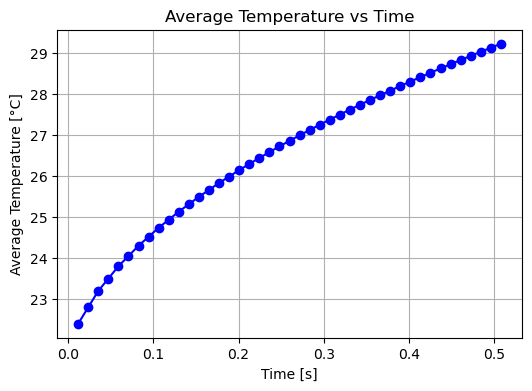

In [2]:
import numpy as np
import matplotlib.pyplot as plt
diffu = 10.8   # (mm^2/s)
length = 50    # mm
time = 0.5
nodes = 100

dx = length / (nodes-1)
dt = 0.5 * dx**2 / diffu
t_nodes = int(time/dt) + 1

u = np.zeros(nodes) + 20 


u[0] = 100
u[-1] = 100

time_vals = []
avg_temps = []


counter = 0
while counter < time:
    w = u.copy()
    for i in range(1, nodes - 1):
        u[i] = w[i] + dt * diffu * (w[i - 1] - 2*w[i] + w[i + 1]) / dx**2

    counter += dt
    time_vals.append(counter)
    avg_temps.append(np.mean(u))
    print(f"Time={counter:2f}, Average Temperature:{np.average(u):2f}")

plt.figure(figsize=(6,4))
plt.plot(time_vals, avg_temps, 'b-o')
plt.xlabel('Time [s]')
plt.ylabel('Average Temperature [°C]')
plt.title('Average Temperature vs Time')
plt.grid(True)
plt.show()


As results are printed and graphed, we can see temperature is increasing as time increases. This is expected behaviour as we know heat diffuses gradually and not instantaneously, we investigate this further in Section **2.3.2**.

### 2.3 2D Finite Difference Method

Building on the 1D framework from **Section 2.2**, we now extend the problem to two dimensions, taking into account the height of each block. Furthermore, we introduce `interface_idx` which is a measuring point between the two blocks, and is the point in the grid where temperatures will be measured during simulation. The time step is defined by the same scheme however, we now take into consideration of $dy$.

Finally, the *for loops* or simulations ensure that each node in the grid is assigned the correct initial temperature and thermal diffusivity, which ultimately categorises it to Aluminum or Steel. This sets up the 2D arrays $u$ (temperature) and `diffu_array` (thermal diffusivity) for the simulation.


In [3]:
al_length = 50     
st_length = 50     
total_length = al_length + st_length  
height = 30 
thickness=1
time = 300
nodes_x = 100    
nodes_y = 40      


dx = total_length / (nodes_x - 1)
dy = height / (nodes_y - 1)


interface_idx = int(al_length / dx)


max_diffu = max(Al['diffu'], St['diffu'])
dt = 0.5 / (max_diffu * (1/dx**2 + 1/dy**2))


u = np.zeros((nodes_y, nodes_x))


for i in range(nodes_x):
    for j in range(nodes_y):
        if i * dx <= al_length:  
            u[j, i] = Al['T_initial']
        else: 
            u[j, i] = St['T_initial']



diffu_array = np.zeros((nodes_y, nodes_x))
for i in range(nodes_x):
    for j in range(nodes_y):
        if i * dx <= al_length: 
            diffu_array[j, i] = Al['diffu']
        else: 
            diffu_array[j, i] = St['diffu']

We can then visualise the system by plotting the initial temperature distribution and a temperature by position graph.

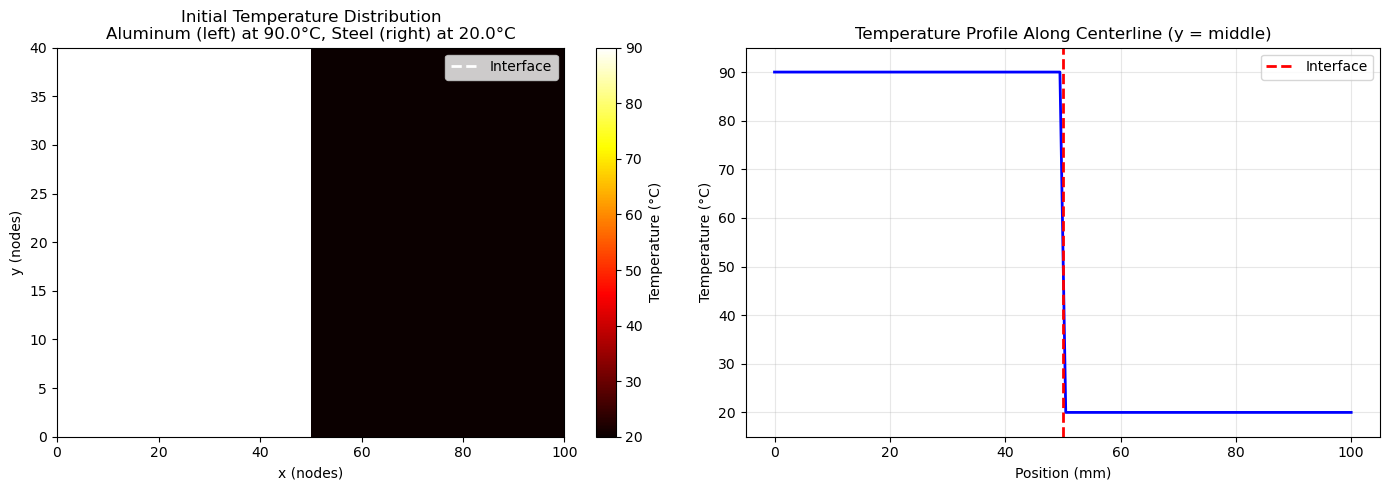

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


pcm1 = ax1.pcolormesh(u, cmap=plt.cm.hot, vmin=min(Al['T_initial'], St['T_initial']), 
                      vmax=max(Al['T_initial'], St['T_initial']))
plt.colorbar(pcm1, ax=ax1, label='Temperature (°C)')
ax1.set_title(f"Initial Temperature Distribution\nAluminum (left) at {Al['T_initial']}°C, Steel (right) at {St['T_initial']}°C")
ax1.set_xlabel('x (nodes)')
ax1.set_ylabel('y (nodes)')
ax1.axvline(x=interface_idx, color='white', linestyle='--', linewidth=2, label='Interface')
ax1.legend()


center_y = nodes_y // 2
x_positions = np.linspace(0, total_length, nodes_x)
line, = ax2.plot(x_positions, u[center_y, :], 'b-', linewidth=2)
ax2.axvline(x=al_length, color='red', linestyle='--', linewidth=2, label='Interface')
ax2.set_xlabel('Position (mm)')
ax2.set_ylabel('Temperature (°C)')
ax2.set_title('Temperature Profile Along Centerline (y = middle)')
ax2.set_ylim(min(Al['T_initial'], St['T_initial']) - 5, max(Al['T_initial'], St['T_initial']) + 5)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.pause(0.1)

The temperature profile of the system at $t=0$ gives us a step graph, however, by definition of thermal equilibrium given in Section **1.2**, we expect this to eventually flatten out at $t=\infty$ as there will be no change in temperature.

Additionally, we are to implement the central finite differences in both $x$ and $y$ directions, which allows the computation of temperatures over time, and hence effectively simulating heat diffusion. We loop this through both directions to analyse all areas of both objects.

Neumann boundary conditions [[7](https://www.resolvedanalytics.com/cfd/what-is-a-neumann-boundary-condition)] are applied along all edges of the domain, addressing zero heat flux and modeling insulated boundaries. This is implemented by equating boundary node temperatures to their adjacent interior values. 
Proceeding, we evaluate the temperature at the interface where the two materials meet by considering values from both the Aluminum (left) and Steel (right) sides. This interface temperature is computed as an average, since there is no single fixed temperature at the boundary. The system does not reach thermal equilibrium instantaneously, but instead, equilibrium is approached asymptotically over time. 
### 2.3.1 Asymptotic Behaviour
This mathematical concept is significant here to describe this behaviour, as we know that a solution to the heat equation takes some form similar to eg.: $u(x,t) = \sum_{n=1}^{\infty} A_n \sin\left(\frac{n\pi x}{L}\right) e^{-n^2\pi^2 k t / L^2}$, We can infer that as $t \to \infty$, one can state that $\lim_{t \to \infty} e^{-n^2 \pi^2 k t / L^2} = 0 \quad \text{for all } n \ge 1 $. Mathematically, it will never reach a steady state of equilibrium however the differences become so minor we can practically regard it as a steady temperature distribution. Importantly, even though a true steady state is impossible, the interface temperatures may appear unchanged from one time step to the next. This apparent stability is due to the differences becoming smaller than the machine’s **floating point precision** [[8](https://medium.com/@goldengrisha/understanding-floating-point-precision-issues-in-python-a-practical-guide-5e17b2f14057)] is making them effectively insignificant.




In [5]:
counter = 0
step_counter = 0
max_steps = int(time / dt) + 1
print("TWO-MATERIAL HEAT TRANSFER SIMULATION")
print("-" * 60)

while counter < time and step_counter < max_steps:
   
    w = u.copy()
    
    
    for i in range(1, nodes_x - 1):
        for j in range(1, nodes_y - 1):
          
            dd_ux = (w[j, i-1] - 2*w[j, i] + w[j, i+1]) / dx**2
            dd_uy = (w[j-1, i] - 2*w[j, i] + w[j+1, i]) / dy**2
            
        
            u[j, i] = dt * diffu_array[j, i] * (dd_ux + dd_uy) + w[j, i]
    

    

    u[:, 0] = u[:, 1]
    

    u[:, -1] = u[:, -2]

    u[0, :] = u[1, :]
    
    u[-1, :] = u[-2, :]
    

    counter += dt

    step_counter += 1
    
   
    interface_temp = np.mean(u[:, interface_idx-1:interface_idx+2])
    
    
    al_avg = np.mean(u[:, :interface_idx])
    st_avg = np.mean(u[:, interface_idx:])
    
    
    if step_counter % 1000 == 0:
        print(f"t: {counter:.1f} s | Al avg: {al_avg:.2f}°C | Interface: {interface_temp:.2f}°C | St avg: {st_avg:.2f}°C")
    
    
    if step_counter % 500 == 0 or step_counter == max_steps:
        pcm1.set_array(u)
        ax1.set_title(f"Temperature Distribution at t = {counter:.1f} s")
        
        line.set_ydata(u[center_y, :])
        ax2.set_title(f'Temperature Profile at t = {counter:.1f} s')
        
        
        text_str = f'Al avg: {al_avg:.1f}°C\nSt avg: {st_avg:.1f}°C\nInterface: {interface_temp:.1f}°C'
        if step_counter == 500:  
            props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
            ax2.text(0.02, 0.98, text_str, transform=ax2.transAxes, fontsize=10,
                    verticalalignment='top', bbox=props)
        else:  
            ax2.texts[0].set_text(text_str)
        
        plt.pause(0.01)
                    

TWO-MATERIAL HEAT TRANSFER SIMULATION
------------------------------------------------------------
t: 2.1 s | Al avg: 74.79°C | Interface: 39.02°C | St avg: 22.22°C
t: 4.1 s | Al avg: 67.94°C | Interface: 38.69°C | St avg: 22.98°C
t: 6.2 s | Al avg: 62.68°C | Interface: 38.47°C | St avg: 23.56°C
t: 8.2 s | Al avg: 58.36°C | Interface: 38.17°C | St avg: 24.04°C
t: 10.3 s | Al avg: 54.73°C | Interface: 37.78°C | St avg: 24.43°C
t: 12.3 s | Al avg: 51.66°C | Interface: 37.32°C | St avg: 24.76°C
t: 14.4 s | Al avg: 49.03°C | Interface: 36.83°C | St avg: 25.05°C
t: 16.5 s | Al avg: 46.78°C | Interface: 36.33°C | St avg: 25.29°C
t: 18.5 s | Al avg: 44.83°C | Interface: 35.83°C | St avg: 25.50°C
t: 20.6 s | Al avg: 43.14°C | Interface: 35.33°C | St avg: 25.69°C
t: 22.6 s | Al avg: 41.66°C | Interface: 34.86°C | St avg: 25.85°C
t: 24.7 s | Al avg: 40.36°C | Interface: 34.41°C | St avg: 25.99°C
t: 26.8 s | Al avg: 39.21°C | Interface: 33.97°C | St avg: 26.11°C
t: 28.8 s | Al avg: 38.20°C | Inte

In [6]:
print(f"Final time: {counter:.1f} s")
print(f"Final Aluminum average: {al_avg:.2f}°C")
print(f"Final Steel average: {st_avg:.2f}°C")
print(f"Final interface temperature: {interface_temp:.2f}°C")
print(f"Temperature difference: {abs(al_avg - st_avg):.2f}°C")

Final time: 300.0 s
Final Aluminum average: 27.43°C
Final Steel average: 27.43°C
Final interface temperature: 27.43°C
Temperature difference: 0.00°C


Lets now visualise this:

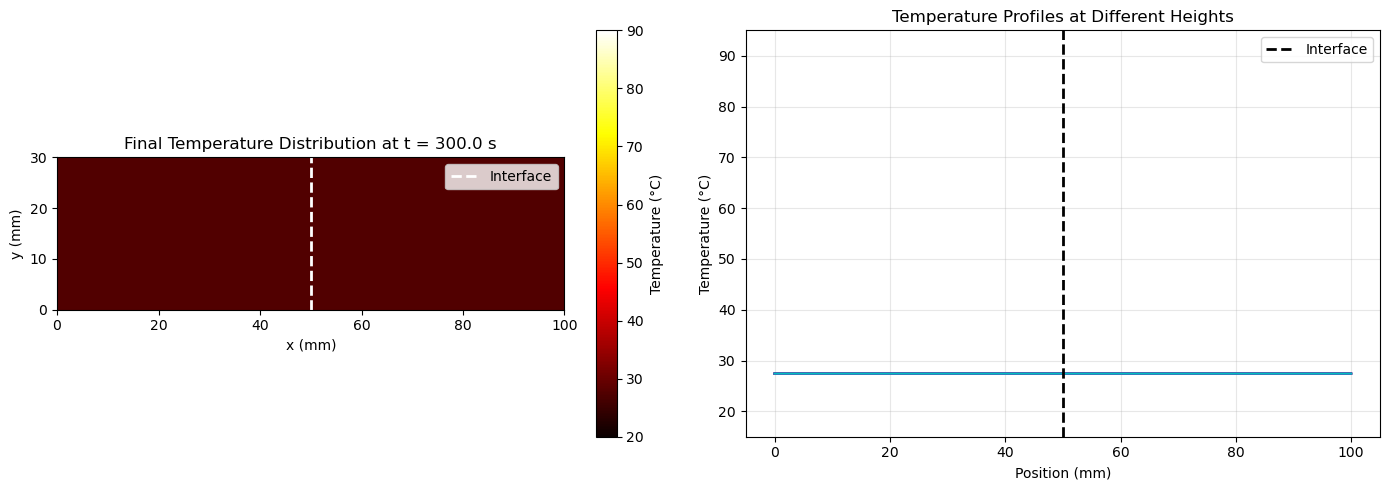

In [7]:
fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(14, 5))


im3 = ax3.imshow(u, cmap='hot', origin='lower', 
                 extent=[0, total_length, 0, height],
                 vmin=min(Al['T_initial'], St['T_initial']), 
                 vmax=max(Al['T_initial'], St['T_initial']))
plt.colorbar(im3, ax=ax3, label='Temperature (°C)')
ax3.set_xlabel('x (mm)')
ax3.set_ylabel('y (mm)')
ax3.set_title(f'Final Temperature Distribution at t = {counter:.1f} s')
ax3.axvline(x=al_length, color='white', linestyle='--', linewidth=2, label='Interface')
ax3.legend()


y_positions = [0, height//4, height//2, 3*height//4, height-1]
colors = ['r-', 'g-', 'b-', 'm-', 'c-']

for idx, y_pos in enumerate(y_positions):
    ax4.plot(x_positions, u[y_pos, :], colors[idx], linewidth=1.5,)

ax4.axvline(x=al_length, color='k', linestyle='--', linewidth=2, label='Interface')
ax4.set_xlabel('Position (mm)')
ax4.set_ylabel('Temperature (°C)')
ax4.set_title('Temperature Profiles at Different Heights')
ax4.set_ylim(min(Al['T_initial'], St['T_initial']) - 5, max(Al['T_initial'], St['T_initial']) + 5)
ax4.grid(True, alpha=0.3)
ax4.legend()

plt.tight_layout()
plt.show()

Interpreting these results we can say from a physical viewpoint that the system is at equilibrium from the nature of the graphs -- a solid colour and a horizontal line. In addition, we can conclude that the final equalised temperature between Steel and Aluminum in the system is approximately **27.43°C**, and approximately took **244.9 s** to reach this steady state.

As the values starting reaching closer to equlibrium, the differences in the interface temperatures became smaller which can give one a gist that it is behaving correctly from Section **2.3.1**.

### 2.3.2 What Occurs Between $t=0$ & $t=\infty$?

Although we understand what has occurred from start to finish, we need to understand how this line was formed, whether it was fairly instantaneous or gradual over time. It's also quite intriguing to see how the system transitions to a straight horizontal line from a steep step graph.

To analyse the temperature–time relationship analytically, we can substitute values for when $t < 244.9$. Out of randomness and simplicity I have substituted $t = 3$. The temperature profile below exhibits a noticeable curvature, in contrast to the sharp step-function observed at $t=0$. This demonstrates that the system approaches thermal equilibrium gradually rather than instantaneously.
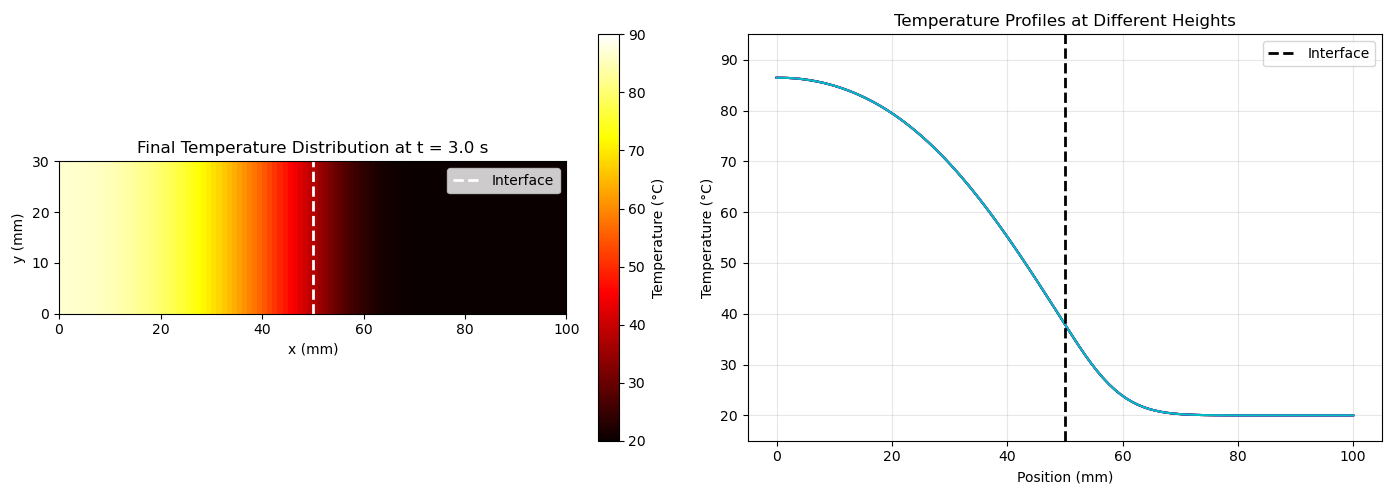8-a5422.4. -93db744fec05.png)

### Entropy

Entropy is a thermodynamic quantity that measures the amount of available energy to do work within a system eg higher entropy means that energy is more disordered and hence less energy is available to do useful work. Examining how entropy varies with temperature provides deeper insight into the microscopic behavior of a system, particularly as it approaches thermal equilibrium. In order to track how entropy changes, we will need to find the volumetric entropy density, defined as; $s = \rho c \ln \left( \frac{T}{T_{\text{ref}}} \right)
$. 

Here we are to investigate how entropy changes with respect to both materials' temperatures. Generative AI has been used to create these lists from the printed values in my code above, just for time efficiency. We then pass these values into a *for loop* to generate values which will be stored in lists to subsequency be visualised.


In [13]:
time = [2.1, 4.1, 6.2, 8.2, 10.3, 12.3, 14.4, 16.5, 18.5, 20.6, 22.6, 24.7, 26.8, 28.8, 30.9, 32.9, 35.0, 37.0, 39.1, 41.2, 43.2, 45.3, 47.3, 49.4, 51.4, 53.5, 55.6, 57.6, 59.7, 61.7,
        63.8, 65.8, 67.9, 70.0, 72.0, 74.1, 76.1, 78.2, 80.3, 82.3, 84.4, 86.4, 88.5, 90.5, 92.6, 94.7, 96.7, 98.8, 100.8, 102.9, 104.9, 107.0, 109.1, 111.1, 113.2, 115.2, 117.3, 119.4, 121.4,
        123.5, 125.5, 127.6, 129.6, 131.7, 133.8, 135.8, 137.9, 139.9, 142.0, 144.0, 146.1, 148.2, 150.2, 152.3, 154.3, 156.4, 158.4, 160.5, 162.6, 164.6, 166.7, 168.7, 170.8, 172.9, 174.9, 177.0,
        179.0, 181.1, 183.1, 185.2, 187.3, 189.3, 191.4, 193.4, 195.5, 197.5, 199.6, 201.7, 203.7, 205.8, 207.8, 209.9, 212.0, 214.0, 216.1, 218.1, 220.2, 222.2, 224.3, 226.4, 228.4, 230.5, 232.5, 234.6,
        236.6, 238.7, 240.8, 242.8, 244.9, 246.9, 249.0, 251.1, 253.1, 255.2, 257.2, 259.3, 261.3, 263.4, 265.5, 267.5, 269.6, 271.6, 273.7, 275.7, 277.8, 279.9, 281.9, 284.0, 286.0, 288.1, 290.1, 292.2,
        294.3, 296.3, 298.4]

al_temp = [74.79, 67.94, 62.68, 58.36, 54.73, 51.66, 49.03, 46.78, 44.83, 43.14, 41.66, 40.36, 39.21, 38.20, 37.29, 36.48, 35.76, 35.11, 34.52, 33.98, 33.50, 33.05, 32.65, 32.27, 31.93, 31.62, 31.33, 
           31.06, 30.81, 30.59, 30.37, 30.18, 29.99, 29.82, 29.66, 29.52, 29.38, 29.25, 29.13, 29.02, 28.92, 28.82, 28.73, 28.65, 28.57, 28.49, 28.42, 28.36, 28.30, 28.24, 28.19, 28.14, 28.09, 28.05, 
           28.01, 27.97, 27.94, 27.91, 27.87, 27.85, 27.82, 27.79, 27.77, 27.75, 27.73, 27.71, 27.69, 27.67, 27.66, 27.64, 27.63, 27.62, 27.60, 27.59, 27.58, 27.57, 27.56, 27.55, 27.54, 27.54, 27.53,
           27.52, 27.52, 27.51, 27.51, 27.50, 27.50, 27.49, 27.49, 27.48, 27.48, 27.48, 27.47, 27.47, 27.47, 27.46, 27.46, 27.46, 27.46, 27.46, 27.45, 27.45, 27.45, 27.45, 27.45, 27.45, 27.44, 27.44,
           27.44, 27.44, 27.44, 27.44, 27.44, 27.44, 27.44, 27.44, 27.44, 27.44, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 
           27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43]

st_temp = [22.22, 22.98, 23.56, 24.04, 24.43, 24.76, 25.05, 25.29, 25.50, 25.69, 25.85, 25.99, 26.11, 26.22, 26.32, 26.41, 26.49, 26.56, 26.63, 26.69, 26.74, 26.79, 26.83, 26.88, 26.91, 26.95, 26.98, 
           27.01, 27.04, 27.07, 27.09, 27.11, 27.13, 27.15, 27.17, 27.19, 27.20, 27.22, 27.23, 27.24, 27.26, 27.27, 27.28, 27.29, 27.30, 27.30, 27.31, 27.32, 27.33, 27.33, 27.34, 27.34, 27.35, 27.35,
           27.36, 27.36, 27.37, 27.37, 27.38, 27.38, 27.38, 27.38, 27.39, 27.39, 27.39, 27.39, 27.40, 27.40, 27.40, 27.40, 27.40, 27.40, 27.41, 27.41, 27.41, 27.41, 27.41, 27.41, 27.41, 27.41, 27.42, 
           27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 27.42, 
           27.42, 27.42, 27.42, 27.42, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 
           27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43, 27.43]

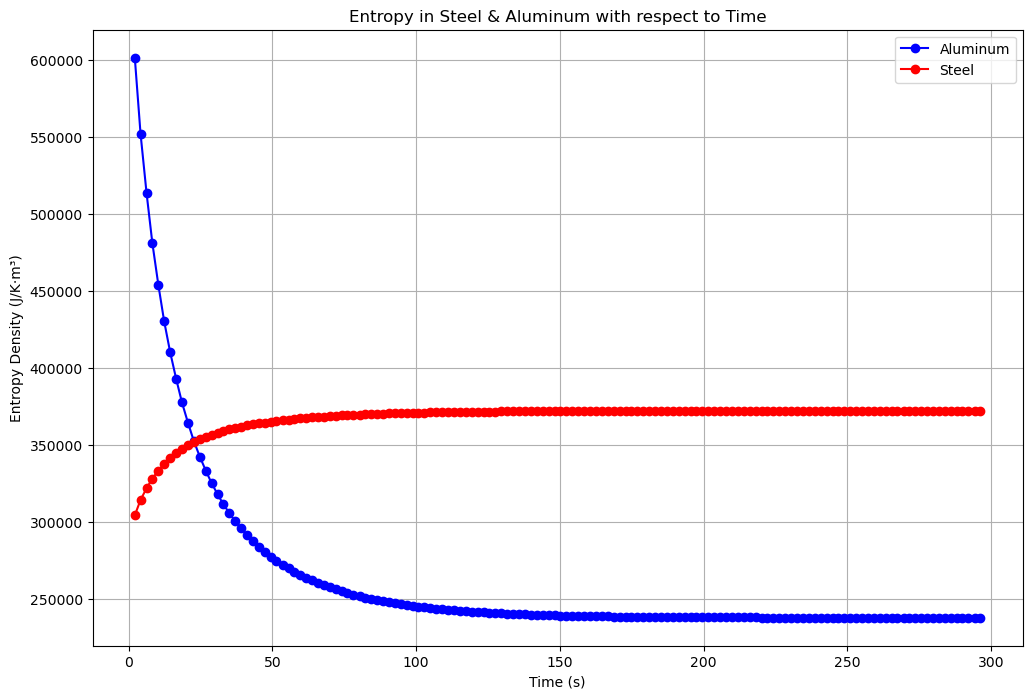

Entropy Analysis
Initial values (t = 2.100000 s):
Aluminum:Temp = 74.790000°C, Entropy = 601357.891071 J/K·m³
Steel:Temp = 22.220000°C, Entropy = 304267.106990 J/K·m³
Final values (t = 296.300000 s):
Aluminum: Temp = 27.430000°C, Entropy = 237783.135576 J/K·m³
Steel: Temp = 27.430000°C, Entropy = 372293.019947 J/K·m³
Entropy changes:
Aluminum:237783.135576 - 601357.891071 J/K·m³
Steel: 372293.019947 - 304267.106990 J/K·m³
Total entropy change: -295548.8425368938 J/K·m³


In [9]:


T_ref = 273.15  

al_entropy = []
st_entropy = []

for i in range(len(al_temp)):
    T_al_K = al_temp[i] + 273.15
    T_st_K = st_temp[i] + 273.15
    
    S_al = Al['rho'] * Al['shc'] * np.log(T_al_K / T_ref)
    S_st = St['rho'] * St['shc'] * np.log(T_st_K / T_ref)
    
    al_entropy.append(S_al)
    st_entropy.append(S_st)

time_plot = time[:len(al_temp)]

plt.figure(figsize=(12, 8))
plt.plot(time_plot, al_entropy, 'b-o', label='Aluminum')
plt.plot(time_plot, st_entropy, 'r-o', label='Steel')
plt.xlabel('Time (s)')
plt.ylabel('Entropy Density (J/K·m³)')
plt.title('Entropy in Steel & Aluminum with respect to Time')
plt.grid(True)
plt.legend()
plt.show()

print("Entropy Analysis")
print(f"Initial values (t = {time_plot[0]:2f} s):")
print(f"Aluminum:Temp = {al_temp[0]:2f}°C, Entropy = {al_entropy[0]:2f} J/K·m³")
print(f"Steel:Temp = {st_temp[0]:2f}°C, Entropy = {st_entropy[0]:2f} J/K·m³")

print(f"Final values (t = {time_plot[-1]:2f} s):")
print(f"Aluminum: Temp = {al_temp[-1]:2f}°C, Entropy = {al_entropy[-1]:2f} J/K·m³")
print(f"Steel: Temp = {st_temp[-1]:2f}°C, Entropy = {st_entropy[-1]:2f} J/K·m³")

print(f"Entropy changes:")
print(f"Aluminum:{al_entropy[-1]:2f} - {al_entropy[0]:2f} J/K·m³")
print(f"Steel: {st_entropy[-1]:2f} - {st_entropy[0]:2f} J/K·m³")

total_initial = al_entropy[0] + st_entropy[0]
total_final = al_entropy[-1]+ st_entropy[-1]
print(f"Total entropy change: {total_final - total_initial} J/K·m³")





The results demonstrate a clear dependence of entropy on temperature within the system. The plot shows a steep decline in the entropy density of aluminum and a gradual increase in that of steel, both occurring within the interval $t<50$. This behaviour is expected as they hold large initial temperature differences. As we are visual beings, we can analyse these graphs further by deducing their gradients to understand the behaviour that each material exhibits in response to this heat exchange. 

The total entropy change obtained for the system is **-295548.84J/K·m³**; however, this should not be interpreted as a violation of the second law of thermodynamics. The decrease in entropy within the system is offset by an increase in the entropy of the surroundings, resulting in an overall positive entropy change for the universe. This is expressed as: $\Delta S_{\text{universe}} = \Delta S_{\text{system}} + \Delta S_{\text{surroundings}} > 0$


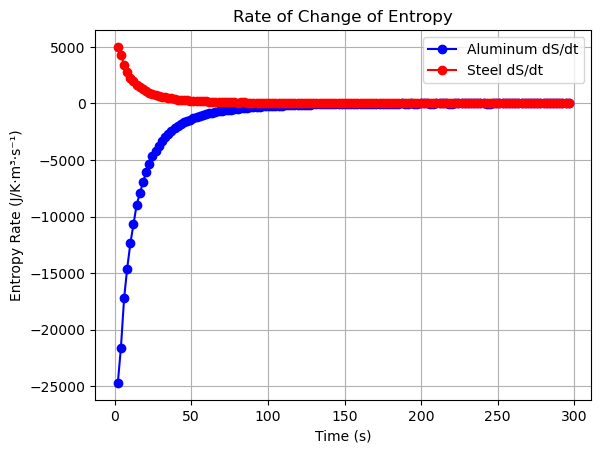

In [10]:

time_arr = np.array(time_plot)
al_entropy_arr = np.array(al_entropy)
st_entropy_arr = np.array(st_entropy)

grad_al = np.gradient(al_entropy_arr, time_arr)  
grad_st = np.gradient(st_entropy_arr, time_arr)  

plt.plot(time_arr, grad_al, 'b-o', label='Aluminum dS/dt')
plt.plot(time_arr, grad_st, 'r-o', label='Steel dS/dt')
plt.xlabel('Time (s)')
plt.ylabel('Entropy Rate (J/K·m³·s⁻¹)')
plt.title('Rate of Change of Entropy')
plt.grid(True)
plt.legend()
plt.show()


Visually we can conclude that the rate of change in entropy in the Aluminum block is alot greater than in Steel. This aligns with the second law of thermodyamics, which we understand to state that the total entropy of an isolated system always increases over time for spontaneous processes [[9](https://openstax.org/books/physics/pages/12-3-second-law-of-thermodynamics-entropy#:~:text=The%20second%20law%20of%20thermodynamics%20states%20that%20the%20total%20entropy,cooler%20to%20a%20hotter%20object.)]. In this case, the Aluminum block heats or cools faster, leading to a larger change in its entropy over the same period, whereas the Steel block changes more slowly, resulting in a smaller entropy gradient.

# 3. Discussion

Returning to our initial scenario, we have concluded analytically and numerically the behaviour of how two objects reach equilibrium in terms of temperature and entropy. Approaching the one dimensional finite difference model was a great introduction to what the finite model is and what is used for. It also allowed me to approach the two dimensional model with increased confidence, nevertheless I did encounter some challenges especially when generating the visualisations in this project. I believe these difficulties stem largely from limited experience, and I thoroughly look forward to reapply the finite different method to future projects.


Furthermore, the results obtained is what I had expected prior starting my project, due to preliminary research. This research came from reading and talking to academics with knowledge about this topic, to which they provided me with some material in order begin. My simulations were an overall success, however, I do acknowledge that there is a handful of limitations to my code that makes it unrealistic to apply in real life cases.

A significant limitation is that the system is in a two dimensional space. This is impossible to demonstrate in an everyday case as we live in a three dimensional world and we would have to amend this code to which is out of my scope of knowledge. In addition, many assumptions were made to make this as basic as possible for one to interpret easily. These assumptions included; no convection or radiation of heat, no external or internal heat sources, however we know that heat will radiate inevitably. This will have to be taken into consideration which is new principles out of my scope of knowledge. 

Simulating the temperature of the interface, Steel and Aluminum was quite lengthy as my defined `time` was around five minutes, this was required as of the temperatures that each material. However, I would like to explore more methods, to somehow speed this simulation due to its inconvenience  in a possible work or research environment. I think in order to save this time is to set each material at lower temperatures but maintain their temperature difference, as it will give the same shape of graphs but decreases the simulation time.

Investigating how entropy changes with temperature in the system was successful and results aligned with the second law of thermodynamics. However, it was quite time consuming organising all temperature values of aluminum and steel into lists. To improve, I would create different data files for each list and import these in to make the code look overall cleaner and save time. However, to further my analysis, investigating entropy with other independent variables would give one a deeper insight of entropy. This could be testing on different diffusivity constants, different lengths etc. 

To investigate further, I would like to see how heat exchange and entropy differs with different materials, varying lengths and height. Although this may be complicated to interpret, it would make an interesting extension to my report!

Lastly, consistently in my printed results I truncated the values typically to 2 decimal points. This is done with the respect of time, as realistically decimals will continue to fluctuate until the system can no longer register a difference. Its unknown how long this would've taken. In the near future, I would like to improve on this code in terms of accuracy, and ultimately making my simulations run quicker if possible. Furthermore, I would like to go into greater depth with computers' limitations, particularity floating point precision error and how disturbing it can be in simulations where accuracy is crucial. 

# 4. Conclusion

Reflecting back to the start of this report, I was quite unsure of how I would approach this problem, however, with the use of resources and guidance, I was able to develop a numerical solution to model the heat exchange between two materials connected at an interface in two dimensions. The finite difference approach to this problem has allowed us to deduced the following findings:

**Time taken for Aluminium and Steel Alloy and Mild (4130 4340) to reach thermal equilibrium**: 244.9 s


**Equalised temperature when initially, Aluminum is at 90°C and Steel at 70°C**:  27.43°C


**The total entropy in the system**: -295548.84J/K·m³

These results were addressed and analysed in an analytical and a mathematical perspective. While applying a two dimensional system to real world systems may present limitations,  the foundations and principles will allow one to approach a three dimensional system in a more straightforward and structured manner.


# References

1.www.grc.nasa.gov. (n.d.). Thermodynamic Equilibrium. [online] Available at: https://www.grc.nasa.gov/www/BGH/thermo0.html.


2.Youtu.be. (2025). Available at: https://youtu.be/CXOrkQs4WYo [Accessed 17 Dec. 2025].


3.Finite Difference Methods (FDM) 3.1 Notations, General Properties. (n.d.). Available at: https://www.wias-berlin.de/people/john/LEHRE/NUMERIK_IV_21_22/num_konv_dom_prob_3.pdf.

4.Berkeley.edu. (2020b). Finite Difference Approximating Derivatives — Python Numerical Methods. [online] Available at: https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter20.02-Finite-Difference-Approximating-Derivatives.html.

5.Youtu.be. (2025). Available at: https://youtu.be/g3Xw1r7QGOE [Accessed 18 Dec. 2025].
6.Thermtest Instruments. (n.d.). Available at: https://thermtest.com/thermal-resources/materials-database#https://www.wjec.co.uk/media/qodcb4vh/investigation-of-the-methods-of-heat-transfer.pdf.

7.Neumann (2020). Resolved Analytics. [online] Resolved Analytics. Available at: https://www.resolvedanalytics.com/cfd/what-is-a-neumann-boundary-condition.

8.Kovalchuk, G. (2024). Understanding Floating-Point Precision Issues in Python: A Practical Guide. [online] Medium. Available at: https://medium.com/@goldengrisha/understanding-floating-point-precision-issues-in-python-a-practical-guide-5e17b2f14057.

9.OpenStax (2020). 12.3 Second Law of Thermodynamics: Entropy - Physics | OpenStax. [online] openstax.org. Available at: https://openstax.org/books/physics/pages/12-3-second-law-of-thermodynamics-entropy.
10.

In [23]:
import nbformat

def word_count(notebook_path):
    """Print word count per Markdown section and total."""
    with open(notebook_path, 'r', encoding='utf-8') as f:
        nb = nbformat.read(f, as_version=4)

    section_words = 0
    total_words = 0

    for cell in nb['cells']:
        if cell['cell_type'] == "markdown":
            for line in cell['source'].split('\n'):
                if line.startswith('#'):
                    print(section_words)
                    total_words += section_words
                    section_words = 0
                    print(line.strip(), end=" ==> ")
                else:
                    section_words += len(line.strip().split())

    print(section_words)
    total_words += section_words
    print("Total ==> ", total_words)
word_count("Untitled1.ipynb")

0
# Heat Flow and Temperature Equalisation: A Finite Difference Approach ==> 4
# 1.Introduction ==> 0
### 1.1 Abstact ==> 80
### 1.2 Thermal Equilibrium ==> 65
### 1.3 The 2D Heat Equation ==> 108
### 1.4 What is the Finite Difference Method ==> 125
# 2. Method & Results ==> 93
### 2.1 Defining Materials ==> 38
### 2.2 Applying the 1D Finite Difference Method ==> 188
### 2.3 2D Finite Difference Method ==> 305
### 2.3.1 Asymptotic Behaviour ==> 232
### 2.3.2 What Occurs Between $t=0$ & $t=\infty$? ==> 105
### Entropy ==> 374
# 3. Discussion ==> 578
# 4. Conclusion ==> 148
# References ==> 103
Total ==>  2546
